In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('wine-clustering.csv')

In [3]:
df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [4]:
df1 = df[['Alcohol','Malic_Acid','Magnesium']]

In [5]:
df1.shape

(178, 3)

<Axes: xlabel='Alcohol', ylabel='Density'>

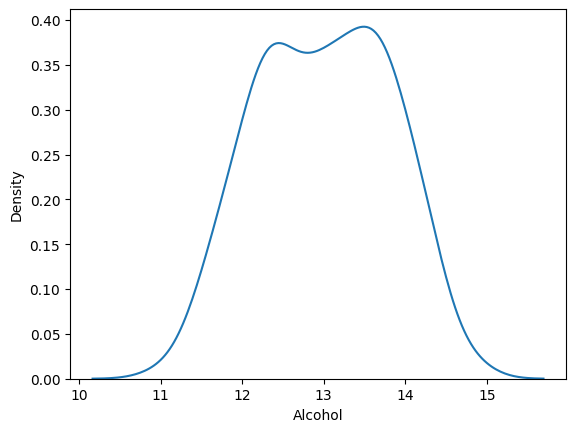

In [6]:
sns.kdeplot(df1['Alcohol'])

<Axes: xlabel='Malic_Acid', ylabel='Density'>

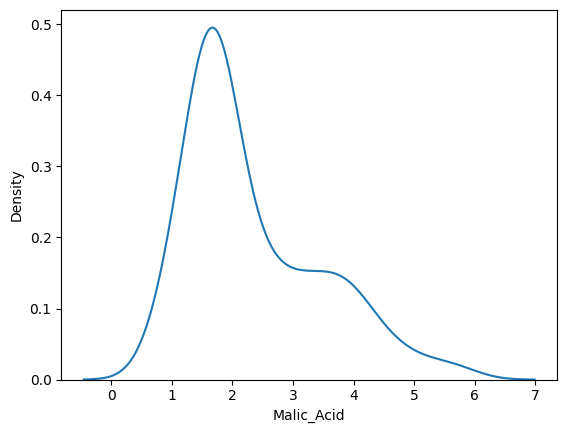

In [13]:
sns.kdeplot(df1['Malic_Acid'])

<Axes: xlabel='Magnesium', ylabel='Density'>

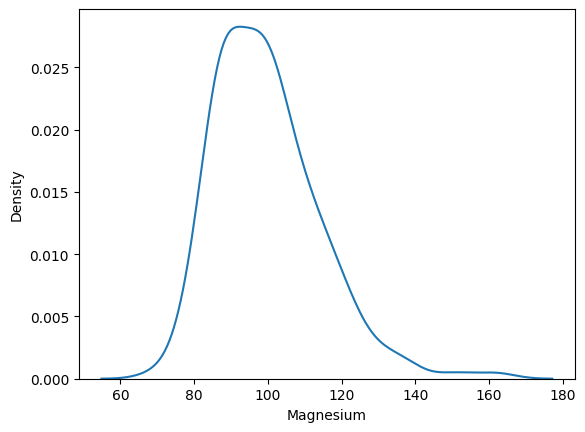

In [14]:
sns.kdeplot(df1['Magnesium'])

<Axes: xlabel='Malic_Acid', ylabel='Alcohol'>

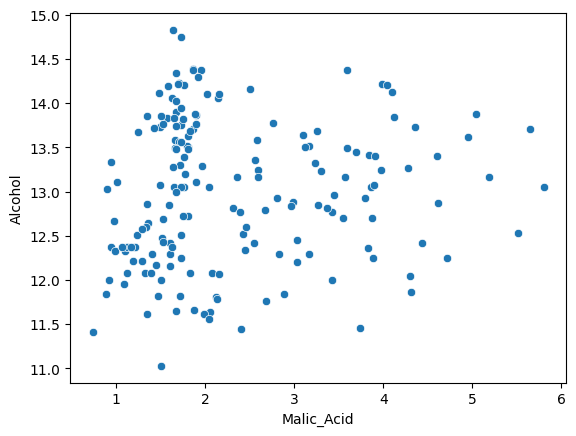

In [15]:
sns.scatterplot(data=df1,x='Malic_Acid',y='Alcohol')

In [18]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(df1.drop(['Magnesium'],axis=1),df1['Magnesium'],test_size=0.3)

In [23]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaler.fit(x_train)

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [25]:
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [26]:
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [31]:
x_train_scaled = pd.DataFrame(scaler.transform(x_train), columns=x_train.columns)
x_test_scaled = pd.DataFrame(scaler.transform(x_test),   columns = x_test.columns)

In [35]:
np.round(x_train.describe())

,Alcohol,Malic_Acid
count,124.0,124.0
mean,13.0,2.0
std,1.0,1.0
min,11.0,1.0
25%,12.0,2.0
50%,13.0,2.0
75%,14.0,3.0
max,15.0,6.0


In [36]:
np.round(x_train_scaled.describe())

,Alcohol,Malic_Acid
count,124.0,124.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,1.0,0.0
max,1.0,1.0


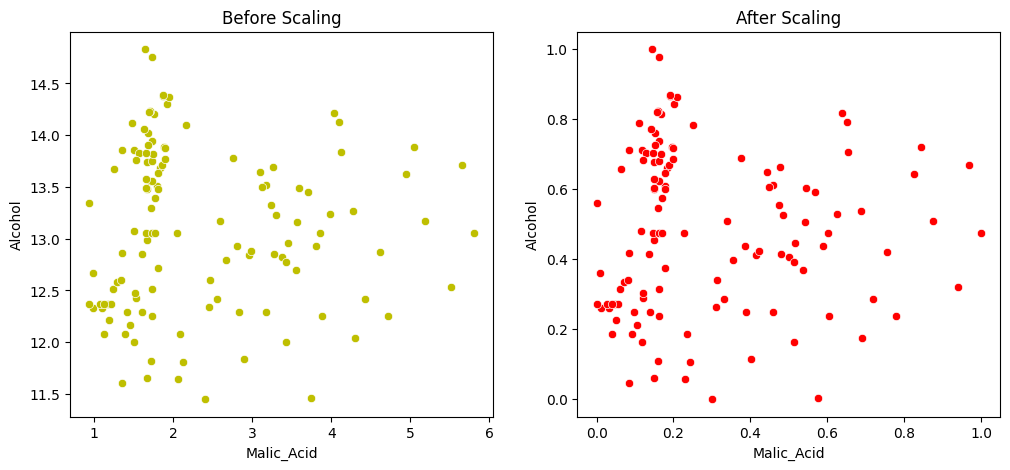

In [40]:
fig , (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))

sns.scatterplot(
    x=x_train['Malic_Acid'],
    y=x_train['Alcohol'],
    color='y',
    ax=ax1
)
ax1.set_title('Before Scaling')

sns.scatterplot(
    x=x_train_scaled['Malic_Acid'],
    y=x_train_scaled['Alcohol'],
    color='r',
    ax=ax2
)
ax2.set_title('After Scaling')

plt.show()

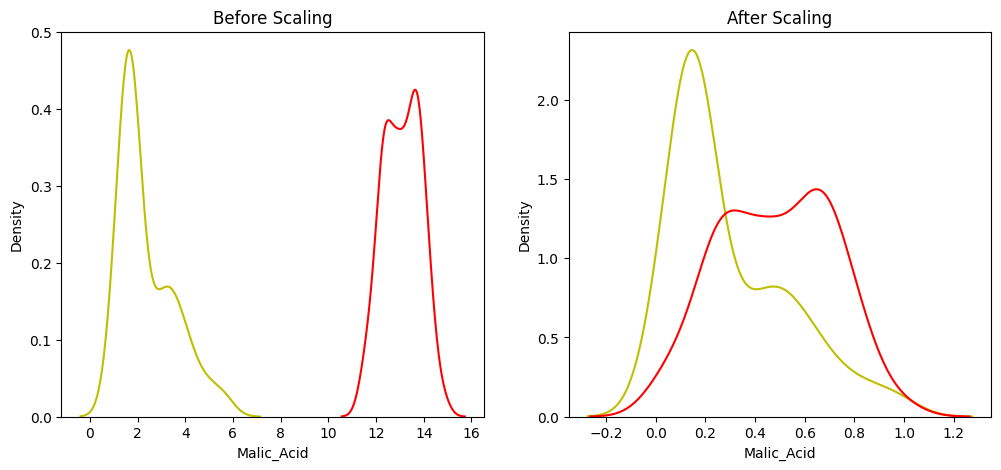

In [46]:
fig , (ax1,ax2) = plt.subplots(ncols=2,figsize=(12,5))

sns.kdeplot(
    x=x_train['Malic_Acid'],
    color='y',
    ax=ax1
)
sns.kdeplot(
    x=x_train['Alcohol'],
    color='r',
    ax=ax1
)
ax1.set_title('Before Scaling')

sns.kdeplot(
    x=x_train_scaled['Malic_Acid'],
    color='y',
    ax=ax2
)
sns.kdeplot(
    x=x_train_scaled['Alcohol'],
    color='r',
    ax=ax2
)
ax2.set_title('After Scaling')

plt.show()

Text(0.5, 1.0, 'alcohol after scaling')

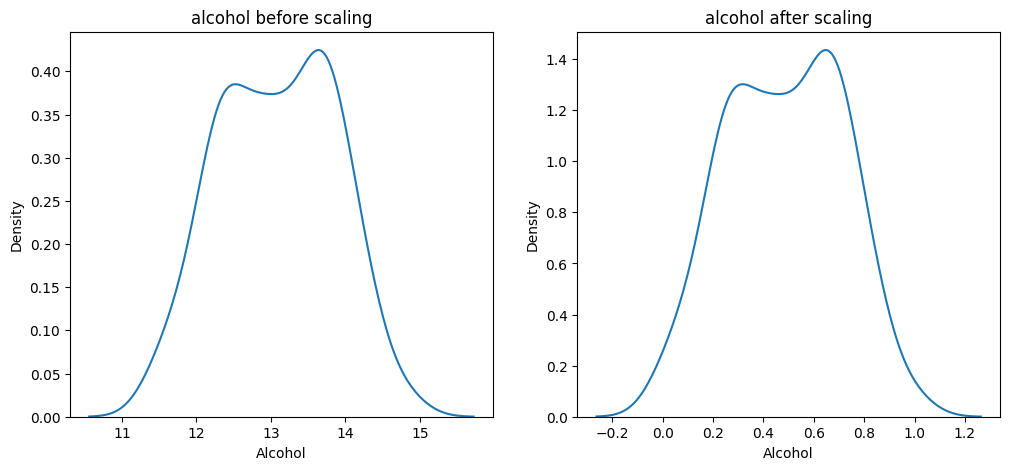

In [53]:
fig , ax = plt.subplots(1,2 , figsize = (12,5))
sns.kdeplot(data=x_train,x='Alcohol',ax=ax[0])
ax[0].set_title('alcohol before scaling')

sns.kdeplot(data=x_train_scaled,x='Alcohol',ax=ax[1])
ax[1].set_title('alcohol after scaling')

Text(0.5, 1.0, 'Malic_Acid after scaling')

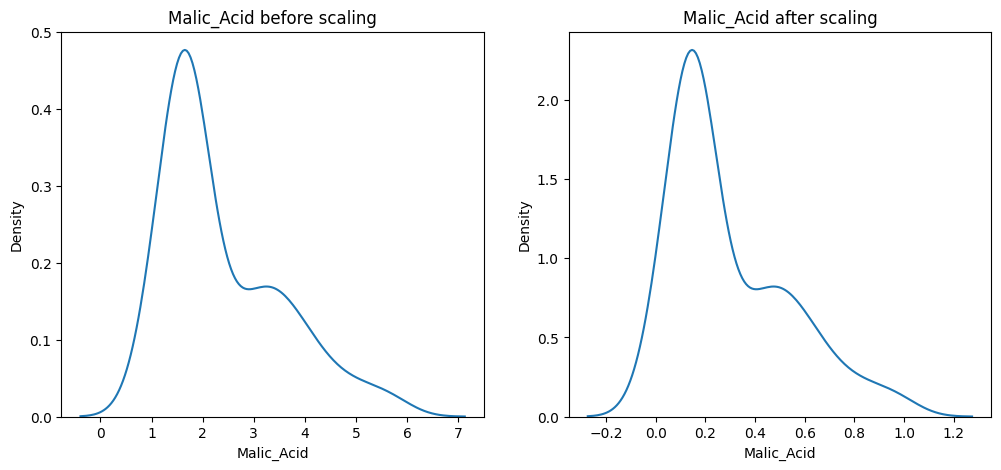

In [54]:
fig , ax = plt.subplots(1,2 , figsize = (12,5))
sns.kdeplot(data=x_train,x='Malic_Acid',ax=ax[0])
ax[0].set_title('Malic_Acid before scaling')

sns.kdeplot(data=x_train_scaled,x='Malic_Acid',ax=ax[1])
ax[1].set_title('Malic_Acid after scaling')